In [269]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier,BaggingClassifier,AdaBoostClassifier,GradientBoostingClassifier)
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

In [270]:
df = pd.read_csv('/content/bank-additional-full.csv')
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [271]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

Checking Null Values

In [272]:
df.isnull().sum() # No null Value

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


Checking Duplicates

In [273]:
df.duplicated().sum()


np.int64(12)

In [274]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [275]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41176.00000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000
mean,40.02380,258.315815,2.567879,962.464810,0.173013,0.081922,93.575720,-40.502863,3.621293,5167.034870
std,10.42068,259.305321,2.770318,186.937102,0.494964,1.570883,0.578839,4.627860,1.734437,72.251364
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [276]:
df.skew(numeric_only=True)

,0
age,0.784560
duration,3.262808
campaign,4.762044
pdays,-4.921386
previous,3.831396
emp.var.rate,-0.724061
cons.price.idx,-0.230853
cons.conf.idx,0.302876
euribor3m,-0.709194
nr.employed,-1.044317


Visualize the Correlation

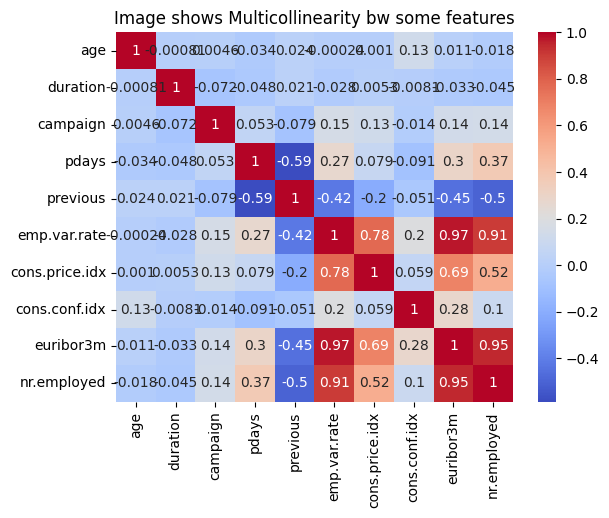

In [277]:
sns.heatmap(df.select_dtypes(include=np.number).corr(),annot=True,cmap="coolwarm")
plt.title("Image shows Multicollinearity bw some features")
plt.show()


In [278]:
#sns.pairplot(df)
#plt.show()

Analysing the Target variable ie (Customer subscription outcome)

In [279]:
df['y'].value_counts(normalize=True)*100   # Target Percentage

,proportion
y,
no,88.733728
yes,11.266272


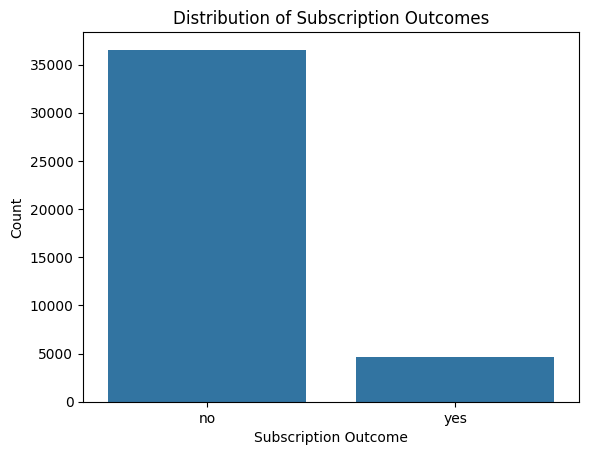

In [280]:
sns.countplot(x='y',data=df)
plt.xlabel('Subscription Outcome')
plt.ylabel('Count')
plt.title('Distribution of Subscription Outcomes')
plt.show()

Checking the Outliers

In [281]:
# Numerical and Catagorical Features

target = 'y'
num_features = df.drop(columns=target).select_dtypes(include=np.number).columns.tolist()
cat_features = df.drop(columns=target).select_dtypes(include='object').columns.tolist()

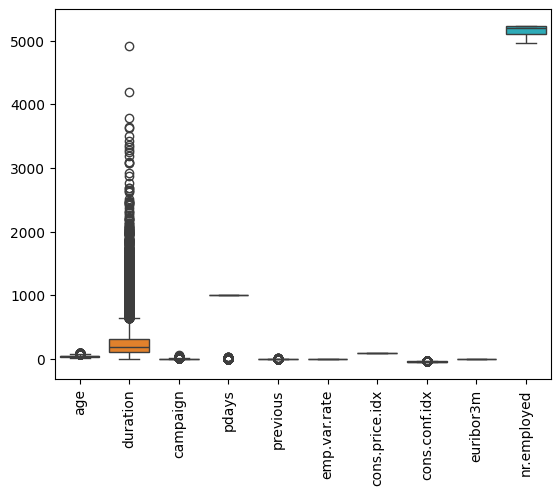

In [282]:
sns.boxplot(data=df[num_features])
plt.xticks(rotation=90)
plt.show()

In [283]:
df[num_features].skew()

,0
age,0.784560
duration,3.262808
campaign,4.762044
pdays,-4.921386
previous,3.831396
emp.var.rate,-0.724061
cons.price.idx,-0.230853
cons.conf.idx,0.302876
euribor3m,-0.709194
nr.employed,-1.044317


Outlier Capping

In [284]:
df[num_features].dtypes


,0
age,int64
duration,int64
campaign,int64
pdays,int64
previous,int64
emp.var.rate,float64
cons.price.idx,float64
cons.conf.idx,float64
euribor3m,float64
nr.employed,float64


In [285]:
for i in num_features:
  Q1 = df[i].quantile(0.25)
  Q3 = df[i].quantile(0.75)
  IQR = Q3-Q1
  lower_limit = Q1-1.5*IQR
  upper_limit = Q3+1.5*IQR
  df.loc[:, i] = df[i].clip(lower=lower_limit,upper=upper_limit)


/tmp/ipykernel_754/1325278679.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[56.  57.  37.  ... 56.  44.  69.5]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[:, i] = df[i].clip(lower=lower_limit,upper=upper_limit)
/tmp/ipykernel_754/1325278679.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[261. 149. 226. ... 189. 442. 239.]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[:, i] = df[i].clip(lower=lower_limit,upper=upper_limit)


In [286]:
df[num_features].skew()

,0
age,0.567396
duration,1.044688
campaign,1.211974
pdays,0.000000
previous,0.000000
emp.var.rate,-0.724061
cons.price.idx,-0.230853
cons.conf.idx,0.300514
euribor3m,-0.709194
nr.employed,-1.044317


Handling Skewness

In [287]:
from sklearn.preprocessing import PowerTransformer
df.loc[:, 'age'] = np.cbrt(df['age'])
df.loc[:, 'duration'] = np.cbrt(df['duration'])
df.loc[:, 'campaign'] = np.cbrt(df['campaign'])
df.loc[:, 'emp.var.rate'] = PowerTransformer(method='yeo-johnson').fit_transform(df[['emp.var.rate']])
df.loc[:, 'euribor3m'] = df['euribor3m'] ** 2
df.loc[:, 'nr.employed'] = df['nr.employed'] ** 2

/tmp/ipykernel_754/1354760912.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[1.         1.         1.         ... 1.25992105 1.         1.44224957]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[:, 'campaign'] = np.cbrt(df['campaign'])


In [288]:
df[num_features].skew()

,0
age,0.225164
duration,0.092369
campaign,0.703139
pdays,0.000000
previous,0.000000
emp.var.rate,-0.414203
cons.price.idx,-0.230853
cons.conf.idx,0.300514
euribor3m,-0.633993
nr.employed,-1.025290


 HANDLE TARGET VARIABLE

In [289]:
df.loc[:, target] = df[target].map({'yes':1,'no':0})

Seperating the Features and Target

In [290]:
X = df.drop(columns=target)
y = df[target]

Encoding and Scaling

In [291]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,3.825862,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1.0,999,0,nonexistent,0.561033,93.994,-36.4,23.590449,26946481.0,0
1,3.848501,services,married,high.school,unknown,no,no,telephone,may,mon,...,1.0,999,0,nonexistent,0.561033,93.994,-36.4,23.590449,26946481.0,0
2,3.332222,services,married,high.school,no,yes,no,telephone,may,mon,...,1.0,999,0,nonexistent,0.561033,93.994,-36.4,23.590449,26946481.0,0
3,3.419952,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1.0,999,0,nonexistent,0.561033,93.994,-36.4,23.590449,26946481.0,0
4,3.825862,services,married,high.school,no,no,yes,telephone,may,mon,...,1.0,999,0,nonexistent,0.561033,93.994,-36.4,23.590449,26946481.0,0


In [292]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [293]:
num_features

['age',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed']

In [294]:
cat_features

['job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'poutcome']

In [295]:
df_enc = pd.get_dummies(df,columns=cat_features,drop_first=True,dtype=int)
df_enc

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,3.825862,6.390677,1.000000,999,0,0.561033,93.994,-36.4,23.590449,26946481.00,...,1,0,0,0,1,0,0,0,1,0
1,3.848501,5.301459,1.000000,999,0,0.561033,93.994,-36.4,23.590449,26946481.00,...,1,0,0,0,1,0,0,0,1,0
2,3.332222,6.091199,1.000000,999,0,0.561033,93.994,-36.4,23.590449,26946481.00,...,1,0,0,0,1,0,0,0,1,0
3,3.419952,5.325074,1.000000,999,0,0.561033,93.994,-36.4,23.590449,26946481.00,...,1,0,0,0,1,0,0,0,1,0
4,3.825862,6.745997,1.000000,999,0,0.561033,93.994,-36.4,23.590449,26946481.00,...,1,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,4.111449,6.938232,1.000000,999,0,-1.013478,94.767,-50.8,1.056784,24637324.96,...,0,1,0,0,0,0,0,0,1,0
41184,3.583048,7.262167,1.000000,999,0,-1.013478,94.767,-50.8,1.056784,24637324.96,...,0,1,0,0,0,0,0,0,1,0
41185,3.825862,5.738794,1.259921,999,0,-1.013478,94.767,-50.8,1.056784,24637324.96,...,0,1,0,0,0,0,0,0,1,0
41186,3.530348,7.617412,1.000000,999,0,-1.013478,94.767,-50.8,1.056784,24637324.96,...,0,1,0,0,0,0,0,0,1,0


In [296]:
df_scaled = df_enc.copy()
scaler = StandardScaler()
df_scaled[num_features] = scaler.fit_transform(df_scaled[num_features])
X = df_scaled.drop(columns=target)
y = df_scaled[target].astype(int)
X


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,1.515836,0.395528,-0.946375,0.0,0.0,0.561033,0.722628,0.886990,0.713496,0.327859,...,1,0,0,0,1,0,0,0,1,0
1,1.595366,-0.300765,-0.946375,0.0,0.0,0.561033,0.722628,0.886990,0.713496,0.327859,...,1,0,0,0,1,0,0,0,1,0
2,-0.218306,0.204084,-0.946375,0.0,0.0,0.561033,0.722628,0.886990,0.713496,0.327859,...,1,0,0,0,1,0,0,0,1,0
3,0.089887,-0.285669,-0.946375,0.0,0.0,0.561033,0.722628,0.886990,0.713496,0.327859,...,1,0,0,0,1,0,0,0,1,0
4,1.515836,0.622669,-0.946375,0.0,0.0,0.561033,0.722628,0.886990,0.713496,0.327859,...,1,0,0,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,2.519093,0.745558,-0.946375,0.0,0.0,-1.013478,2.058076,-2.225706,-1.439241,-2.787541,...,0,1,0,0,0,0,0,0,1,0
41184,0.662837,0.952636,-0.946375,0.0,0.0,-1.013478,2.058076,-2.225706,-1.439241,-2.787541,...,0,1,0,0,0,0,0,0,1,0
41185,1.515836,-0.021195,0.012202,0.0,0.0,-1.013478,2.058076,-2.225706,-1.439241,-2.787541,...,0,1,0,0,0,0,0,0,1,0
41186,0.477706,1.179730,-0.946375,0.0,0.0,-1.013478,2.058076,-2.225706,-1.439241,-2.787541,...,0,1,0,0,0,0,0,0,1,0


In [297]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
X_train.shape,X_test.shape,y_train.shape,y_test.shape


((32940, 53), (8236, 53), (32940,), (8236,))

Applying Classification Models

In [298]:
# Logestic Regression

lr = LogisticRegression()
lr.fit(X_train,y_train)
lr_ypred = lr.predict(X_test)


In [299]:
# K-Nearest Neighbors (KNN)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_ypred = knn.predict(X_test)


In [300]:
# SVM
from sklearn.svm import LinearSVC
svm = LinearSVC(C=1,class_weight='balanced',max_iter=5000,random_state=42)
svm.fit(X_train, y_train)
svm_ypred = svm.predict(X_test)


In [301]:
# Decision Tree

dt = DecisionTreeClassifier(max_depth=8,random_state=42,class_weight='balanced')
dt.fit(X_train, y_train)
dt_ypred = dt.predict(X_test)


Ensemble Learning Models

In [302]:
# Random Forest

rf = RandomForestClassifier(n_estimators=100,max_depth=8,random_state=42,class_weight='balanced')
rf.fit(X_train, y_train)
rf_ypred = rf.predict(X_test)


In [304]:
# Bagging Classifier

bc = BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=8),n_estimators=50,random_state=42,n_jobs=1)
bc.fit(X_train, y_train)
bc_ypred = bc.predict(X_test)

In [306]:
# AdaBoost Classifier

ada = AdaBoostClassifier(n_estimators=100,learning_rate=0.1,random_state=42)
ada.fit(X_train, y_train)
ada_ypred = ada.predict(X_test)


In [307]:
# Gradient Boosting Classifier

gb = GradientBoostingClassifier(max_depth=3,n_estimators=100,learning_rate=0.1,random_state=42)
gb.fit(X_train, y_train)
gb_ypred = gb.predict(X_test)

Model evaluation (Accuracy, Precision, Recall, F1-score)

In [317]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report)
models = {'Logistic Regression':lr_ypred, 'KNN':knn_ypred, 'SVM':svm_ypred, 'Decision Tree':dt_ypred, 'Random Forest':rf_ypred, 'Bagging':bc_ypred, 'AdaBoost':ada_ypred, 'Gradient Boosting':gb_ypred}

result = []
for name,predictions in models.items():
  accuracy = accuracy_score(y_test, predictions)
  precision = precision_score(y_test,predictions,zero_division=0)
  recall = recall_score(y_test,predictions,zero_division=0)
  f1 = f1_score(y_test,predictions,zero_division=0)

  result.append({'Model':name,'Accuracy':accuracy,'Precision':precision,'Recall':recall,'F1 Score':f1})

result_df = pd.DataFrame(result)
result_df.sort_values(by='F1 Score',ascending=False)


,Model,Accuracy,Precision,Recall,F1 Score
4,Random Forest,0.852113,0.429337,0.949353,0.591275
7,Gradient Boosting,0.915736,0.661157,0.517241,0.580411
2,SVM,0.844585,0.415222,0.928879,0.573901
3,Decision Tree,0.845313,0.416019,0.923491,0.573628
5,Bagging,0.913307,0.656433,0.483836,0.557072
1,KNN,0.900923,0.586687,0.408405,0.481576
0,Logistic Regression,0.905658,0.632689,0.387931,0.480962
6,AdaBoost,0.895095,0.668421,0.136853,0.227191


Visualize the Model

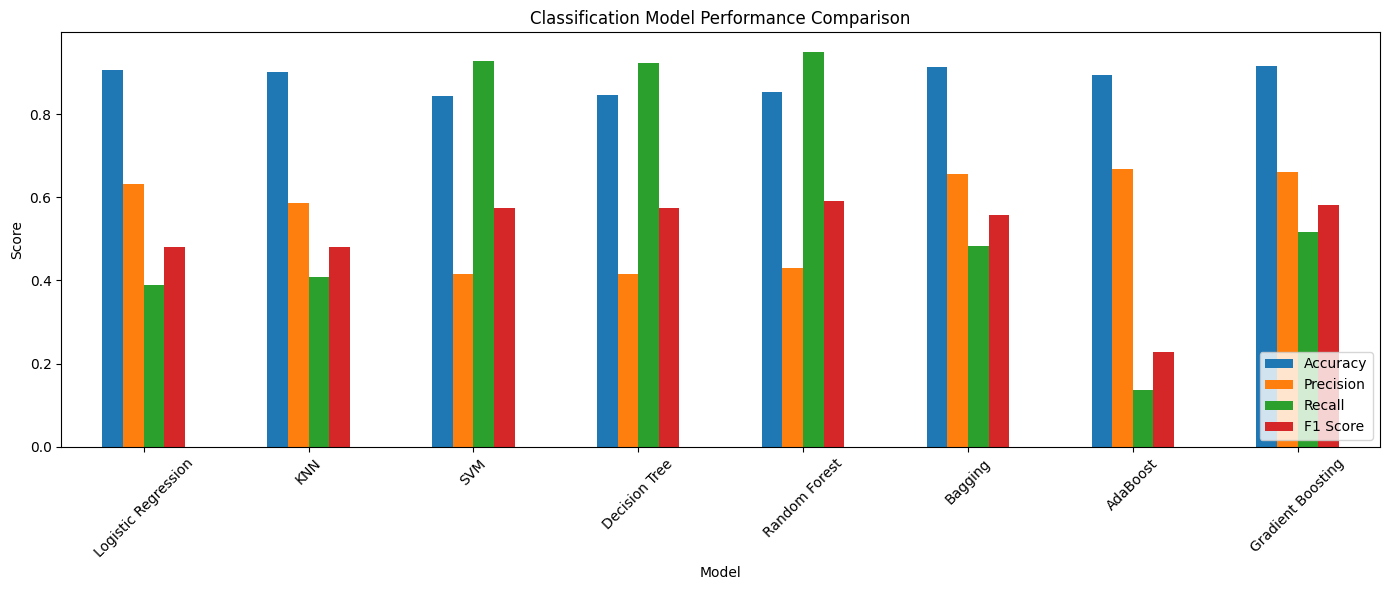

In [319]:
result_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(kind='bar', figsize=(14, 6))

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Best Performing Model

In [321]:
best_model = result_df.sort_values(by='F1 Score',ascending=False).iloc[0]

print("Best Model:", best_model['Model'])

print("Accuracy:", best_model['Accuracy'])

print("Precision:", best_model['Precision'])

print("Recall:", best_model['Recall'])

print("F1 Score:", best_model['F1 Score'])

Best Model: Random Forest
Accuracy: 0.852112676056338
Precision: 0.4293372319688109
Recall: 0.9493534482758621
F1 Score: 0.5912751677852349


Classification Report

In [322]:
best_model_name = best_model['Model']

best_predictions = models[best_model_name]

print(classification_report(
    y_test,
    best_predictions,
    target_names=['Not Subscribed', 'Subscribed']
))

                precision    recall  f1-score   support

Not Subscribed       0.99      0.84      0.91      7308
    Subscribed       0.43      0.95      0.59       928

      accuracy                           0.85      8236
     macro avg       0.71      0.89      0.75      8236
  weighted avg       0.93      0.85      0.87      8236



Feature that influence the Subscription

In [328]:
feature_importance = pd.DataFrame({'Feature': X_train.columns,'Importance': rf.feature_importances_})

feature_importance = feature_importance.sort_values(by='Importance',ascending=False)

print(feature_importance.head(15))

                 Feature  Importance
1               duration    0.415178
9            nr.employed    0.130510
8              euribor3m    0.119026
5           emp.var.rate    0.074841
7          cons.conf.idx    0.049947
6         cons.price.idx    0.037239
52      poutcome_success    0.032505
51  poutcome_nonexistent    0.020867
37     contact_telephone    0.019583
43             month_may    0.015076
0                    age    0.014329
45             month_oct    0.009241
31       default_unknown    0.007905
42             month_mar    0.005935
2               campaign    0.005308


Visualize Feature Importance

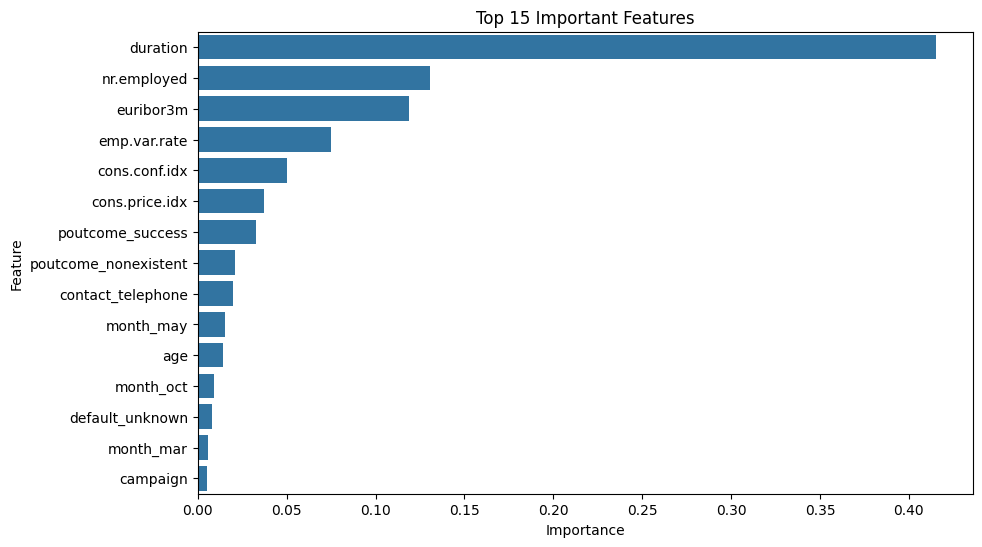

In [329]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features")
plt.show()

In [333]:
lr_coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr.coef_[0]
})

lr_coefficients['Absolute_Coefficient'] = (
    lr_coefficients['Coefficient'].abs()
)

lr_coefficients = lr_coefficients.sort_values(
    by='Absolute_Coefficient',
    ascending=False
)

print(lr_coefficients.head(15))     # Larger absolute coefficients indicate stronger influence in the logistic regression model

                 Feature  Coefficient  Absolute_Coefficient
52      poutcome_success     2.025889              2.025889
5           emp.var.rate    -1.916052              1.916052
1               duration     1.847864              1.847864
8              euribor3m     1.835454              1.835454
42             month_mar     1.752904              1.752904
9            nr.employed    -1.099472              1.099472
44             month_nov    -0.889762              0.889762
43             month_may    -0.784164              0.784164
38             month_aug     0.649317              0.649317
41             month_jun     0.645083              0.645083
40             month_jul     0.573159              0.573159
51  poutcome_nonexistent     0.428773              0.428773
14           job_retired     0.416814              0.416814
37     contact_telephone    -0.353367              0.353367
27  education_illiterate     0.310154              0.310154


Confusion matrix

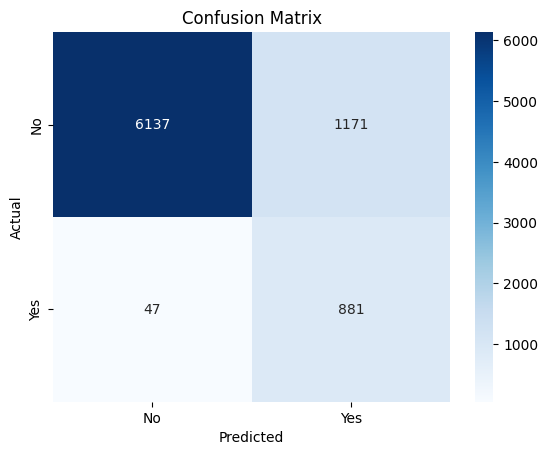

In [334]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, best_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
# True Positive Correctly predicted subscribed customers.
# True Negative Correctly predicted non-subscribers.
# False Positive Predicted subscribed but actually not subscribed.
# False Negative Predicted not subscribed but actually subscribed.

Business insights

In [ ]:
## From the Graph (Feature Importance) focus on first 7 features to improve Subscription of term deposit.##